In [29]:
import pandas as pd #data manipulation
import numpy as np #numerical computations
from sklearn.model_selection import train_test_split # scikit-learn fo
from sklearn import metrics
import matplotlib.pyplot as plt

In [2]:
df= pd.read_csv("Telecom.csv")


In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.shape

(7043, 21)

In [7]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [8]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [9]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [10]:
num_cols = df.select_dtypes(include=['int64','float64']).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].mean())

In [11]:
cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [13]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df = df.drop_duplicates()

In [16]:
for col in cat_cols:
    df[col] = df[col].str.strip()

In [17]:
for col in cat_cols:
    df[col] = df[col].str.lower()

In [18]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-vhveg,female,0,yes,no,1,no,no phone service,dsl,no,...,no,no,no,no,month-to-month,yes,electronic check,29.85,29.85,no
1,5575-gnvde,male,0,no,no,34,yes,no,dsl,yes,...,yes,no,no,no,one year,no,mailed check,56.95,1889.50,no
2,3668-qpybk,male,0,no,no,2,yes,no,dsl,yes,...,no,no,no,no,month-to-month,yes,mailed check,53.85,108.15,yes
3,7795-cfocw,male,0,no,no,45,no,no phone service,dsl,yes,...,yes,yes,no,no,one year,no,bank transfer (automatic),42.30,1840.75,no
4,9237-hqitu,female,0,no,no,2,yes,no,fiber optic,no,...,no,no,no,no,month-to-month,yes,electronic check,70.70,151.65,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-resvb,male,0,yes,yes,24,yes,yes,dsl,yes,...,yes,yes,yes,yes,one year,yes,mailed check,84.80,1990.50,no
7039,2234-xaduh,female,0,yes,yes,72,yes,yes,fiber optic,no,...,yes,no,yes,yes,one year,yes,credit card (automatic),103.20,7362.90,no
7040,4801-jzazl,female,0,yes,yes,11,no,no phone service,dsl,yes,...,no,no,no,no,month-to-month,yes,electronic check,29.60,346.45,no
7041,8361-ltmkd,male,1,yes,no,4,yes,yes,fiber optic,no,...,no,no,no,no,month-to-month,yes,mailed check,74.40,306.60,yes


In [19]:
for col in cat_cols:
    df[col] = df[col].str.upper()

In [20]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,FEMALE,0,YES,NO,1,NO,NO PHONE SERVICE,DSL,NO,...,NO,NO,NO,NO,MONTH-TO-MONTH,YES,ELECTRONIC CHECK,29.85,29.85,NO
1,5575-GNVDE,MALE,0,NO,NO,34,YES,NO,DSL,YES,...,YES,NO,NO,NO,ONE YEAR,NO,MAILED CHECK,56.95,1889.50,NO
2,3668-QPYBK,MALE,0,NO,NO,2,YES,NO,DSL,YES,...,NO,NO,NO,NO,MONTH-TO-MONTH,YES,MAILED CHECK,53.85,108.15,YES
3,7795-CFOCW,MALE,0,NO,NO,45,NO,NO PHONE SERVICE,DSL,YES,...,YES,YES,NO,NO,ONE YEAR,NO,BANK TRANSFER (AUTOMATIC),42.30,1840.75,NO
4,9237-HQITU,FEMALE,0,NO,NO,2,YES,NO,FIBER OPTIC,NO,...,NO,NO,NO,NO,MONTH-TO-MONTH,YES,ELECTRONIC CHECK,70.70,151.65,YES
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,MALE,0,YES,YES,24,YES,YES,DSL,YES,...,YES,YES,YES,YES,ONE YEAR,YES,MAILED CHECK,84.80,1990.50,NO
7039,2234-XADUH,FEMALE,0,YES,YES,72,YES,YES,FIBER OPTIC,NO,...,YES,NO,YES,YES,ONE YEAR,YES,CREDIT CARD (AUTOMATIC),103.20,7362.90,NO
7040,4801-JZAZL,FEMALE,0,YES,YES,11,NO,NO PHONE SERVICE,DSL,YES,...,NO,NO,NO,NO,MONTH-TO-MONTH,YES,ELECTRONIC CHECK,29.60,346.45,NO
7041,8361-LTMKD,MALE,1,YES,NO,4,YES,YES,FIBER OPTIC,NO,...,NO,NO,NO,NO,MONTH-TO-MONTH,YES,MAILED CHECK,74.40,306.60,YES


In [21]:
df.dtypes               # to check the datatype

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

In [22]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [23]:
df["Churn"] = df["Churn"].map({"YES":1,"NO":0})

In [24]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

In [25]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,FEMALE,0,YES,NO,1,NO,NO PHONE SERVICE,DSL,NO,...,NO,NO,NO,NO,MONTH-TO-MONTH,YES,ELECTRONIC CHECK,29.85,29.85,0
1,5575-GNVDE,MALE,0,NO,NO,34,YES,NO,DSL,YES,...,YES,NO,NO,NO,ONE YEAR,NO,MAILED CHECK,56.95,1889.50,0
2,3668-QPYBK,MALE,0,NO,NO,2,YES,NO,DSL,YES,...,NO,NO,NO,NO,MONTH-TO-MONTH,YES,MAILED CHECK,53.85,108.15,1
3,7795-CFOCW,MALE,0,NO,NO,45,NO,NO PHONE SERVICE,DSL,YES,...,YES,YES,NO,NO,ONE YEAR,NO,BANK TRANSFER (AUTOMATIC),42.30,1840.75,0
4,9237-HQITU,FEMALE,0,NO,NO,2,YES,NO,FIBER OPTIC,NO,...,NO,NO,NO,NO,MONTH-TO-MONTH,YES,ELECTRONIC CHECK,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,MALE,0,YES,YES,24,YES,YES,DSL,YES,...,YES,YES,YES,YES,ONE YEAR,YES,MAILED CHECK,84.80,1990.50,0
7039,2234-XADUH,FEMALE,0,YES,YES,72,YES,YES,FIBER OPTIC,NO,...,YES,NO,YES,YES,ONE YEAR,YES,CREDIT CARD (AUTOMATIC),103.20,7362.90,0
7040,4801-JZAZL,FEMALE,0,YES,YES,11,NO,NO PHONE SERVICE,DSL,YES,...,NO,NO,NO,NO,MONTH-TO-MONTH,YES,ELECTRONIC CHECK,29.60,346.45,0
7041,8361-LTMKD,MALE,1,YES,NO,4,YES,YES,FIBER OPTIC,NO,...,NO,NO,NO,NO,MONTH-TO-MONTH,YES,MAILED CHECK,74.40,306.60,1


In [27]:
num_cols = df.select_dtypes(include=np.number).columns       #Select numerical columns

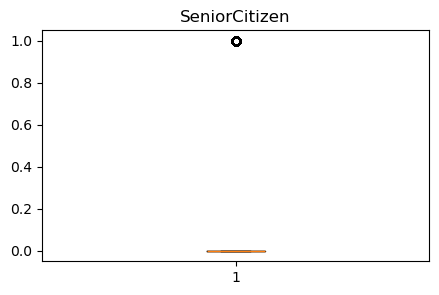

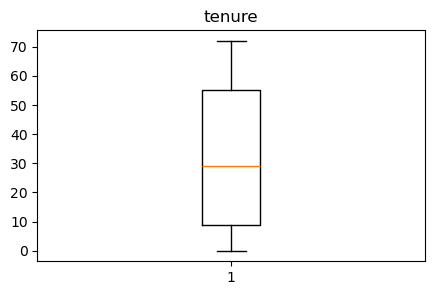

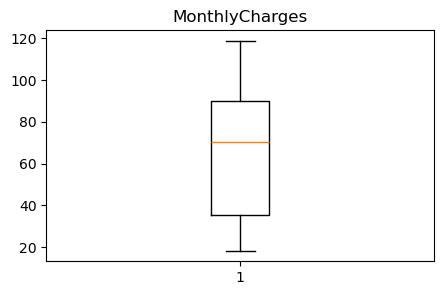

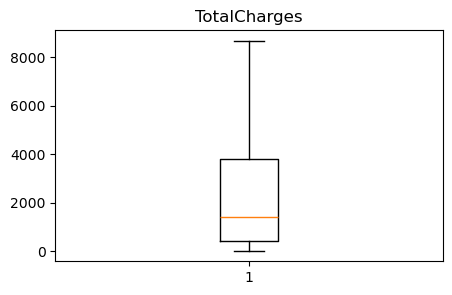

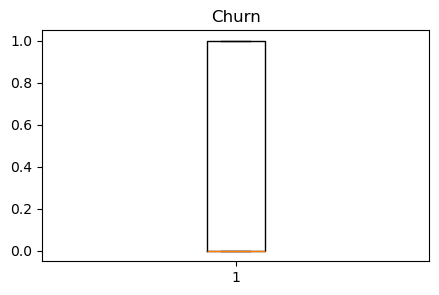

In [30]:
for col in num_cols:
    plt.figure(figsize=(5,3))
    plt.boxplot(df[col].dropna())
    plt.title(col)
    plt.show()

In [31]:
for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower) & (df[col] <= upper)]

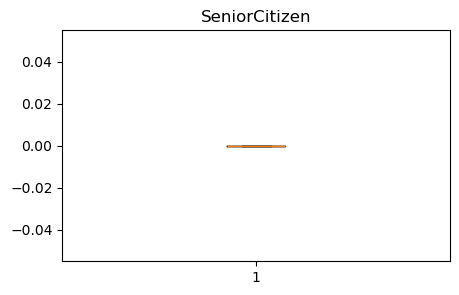

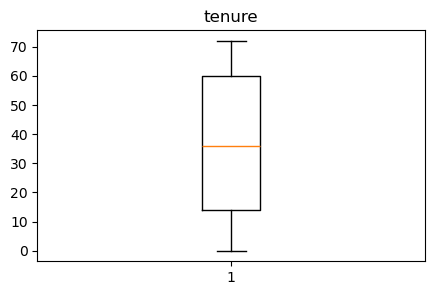

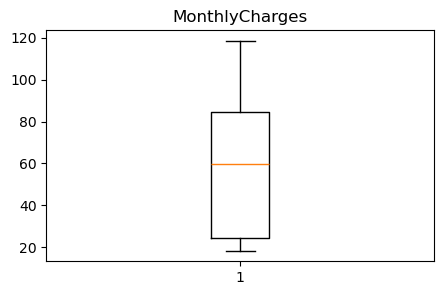

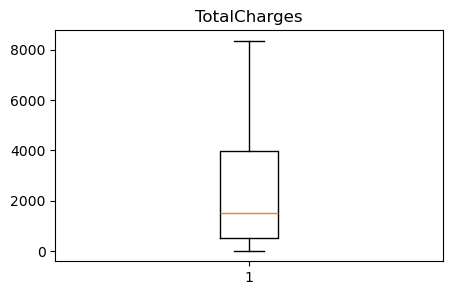

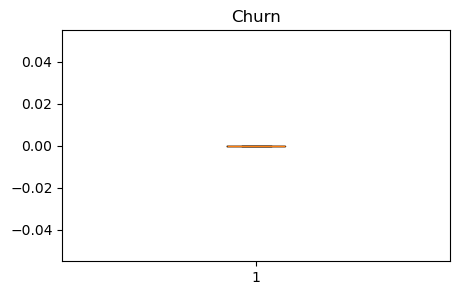

In [32]:
# after remove outliers
for col in num_cols:
    plt.figure(figsize=(5,3))
    plt.boxplot(df[col].dropna())
    plt.title(col)
    plt.show()

In [33]:
df["Charge_per_Tenure"] = df["MonthlyCharges"] / (df["tenure"] + 1)  #Create Monthly Charge per Tenure

In [34]:
# Create Total Services
services = [
    "PhoneService",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["TotalServices"] = df[services].apply(lambda x: (x=="yes").sum(), axis=1)

In [35]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Charge_per_Tenure,TotalServices
0,7590-VHVEG,FEMALE,0,YES,NO,1,NO,NO PHONE SERVICE,DSL,NO,...,NO,NO,MONTH-TO-MONTH,YES,ELECTRONIC CHECK,29.85,29.85,0,14.925000,0
1,5575-GNVDE,MALE,0,NO,NO,34,YES,NO,DSL,YES,...,NO,NO,ONE YEAR,NO,MAILED CHECK,56.95,1889.50,0,1.627143,0
3,7795-CFOCW,MALE,0,NO,NO,45,NO,NO PHONE SERVICE,DSL,YES,...,NO,NO,ONE YEAR,NO,BANK TRANSFER (AUTOMATIC),42.30,1840.75,0,0.919565,0
6,1452-KIOVK,MALE,0,NO,YES,22,YES,YES,FIBER OPTIC,NO,...,YES,NO,MONTH-TO-MONTH,YES,CREDIT CARD (AUTOMATIC),89.10,1949.40,0,3.873913,0
7,6713-OKOMC,FEMALE,0,NO,NO,10,NO,NO PHONE SERVICE,DSL,YES,...,NO,NO,MONTH-TO-MONTH,NO,MAILED CHECK,29.75,301.90,0,2.704545,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7037,2569-WGERO,FEMALE,0,NO,NO,72,YES,NO,NO,NO INTERNET SERVICE,...,NO INTERNET SERVICE,NO INTERNET SERVICE,TWO YEAR,YES,BANK TRANSFER (AUTOMATIC),21.15,1419.40,0,0.289726,0
7038,6840-RESVB,MALE,0,YES,YES,24,YES,YES,DSL,YES,...,YES,YES,ONE YEAR,YES,MAILED CHECK,84.80,1990.50,0,3.392000,0
7039,2234-XADUH,FEMALE,0,YES,YES,72,YES,YES,FIBER OPTIC,NO,...,YES,YES,ONE YEAR,YES,CREDIT CARD (AUTOMATIC),103.20,7362.90,0,1.413699,0
7040,4801-JZAZL,FEMALE,0,YES,YES,11,NO,NO PHONE SERVICE,DSL,YES,...,NO,NO,MONTH-TO-MONTH,YES,ELECTRONIC CHECK,29.60,346.45,0,2.466667,0


In [42]:
df = pd.get_dummies(df, drop_first=True)

In [43]:
df

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,Charge_per_Tenure,TotalServices,customerID_0003-MKNFE,customerID_0013-MHZWF,customerID_0014-BMAQU,...,StreamingTV_NO INTERNET SERVICE,StreamingTV_YES,StreamingMovies_NO INTERNET SERVICE,StreamingMovies_YES,Contract_ONE YEAR,Contract_TWO YEAR,PaperlessBilling_YES,PaymentMethod_CREDIT CARD (AUTOMATIC),PaymentMethod_ELECTRONIC CHECK,PaymentMethod_MAILED CHECK
0,0,1,29.85,29.85,0,14.925000,0,False,False,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,1.627143,0,False,False,False,...,False,False,False,False,True,False,False,False,False,True
3,0,45,42.30,1840.75,0,0.919565,0,False,False,False,...,False,False,False,False,True,False,False,False,False,False
6,0,22,89.10,1949.40,0,3.873913,0,False,False,False,...,False,True,False,False,False,False,True,True,False,False
7,0,10,29.75,301.90,0,2.704545,0,False,False,False,...,False,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7037,0,72,21.15,1419.40,0,0.289726,0,False,False,False,...,True,False,True,False,False,True,True,False,False,False
7038,0,24,84.80,1990.50,0,3.392000,0,False,False,False,...,False,True,False,True,True,False,True,False,False,True
7039,0,72,103.20,7362.90,0,1.413699,0,False,False,False,...,False,True,False,True,True,False,True,True,False,False
7040,0,11,29.60,346.45,0,2.466667,0,False,False,False,...,False,False,False,False,False,False,True,False,True,False


In [44]:
from sklearn.preprocessing import MinMaxScaler     #Import scaler

In [45]:
scaler = MinMaxScaler()                             #Create scaler

In [47]:
num_cols = df.select_dtypes(include=np.number).columns

df[num_cols] = scaler.fit_transform(df[num_cols])         #Scale numerical columns

In [48]:
from sklearn.model_selection import train_test_split

In [50]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42            #split
)

In [53]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)     #check shapes

(3592, 4521)
(898, 4521)
(3592,)
(898,)


In [54]:
df.to_csv("Telecom_Customer_Churn_Cleaned.csv", index=False)

In [55]:
df

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,Charge_per_Tenure,TotalServices,customerID_0003-MKNFE,customerID_0013-MHZWF,customerID_0014-BMAQU,...,StreamingTV_NO INTERNET SERVICE,StreamingTV_YES,StreamingMovies_NO INTERNET SERVICE,StreamingMovies_YES,Contract_ONE YEAR,Contract_TWO YEAR,PaperlessBilling_YES,PaymentMethod_CREDIT CARD (AUTOMATIC),PaymentMethod_ELECTRONIC CHECK,PaymentMethod_MAILED CHECK
0,0.0,0.013889,0.115595,0.001326,0.0,0.181926,0.0,False,False,False,...,False,False,False,False,False,False,True,False,True,False
1,0.0,0.472222,0.385650,0.224550,0.0,0.016911,0.0,False,False,False,...,False,False,False,False,True,False,False,False,False,True
3,0.0,0.625000,0.239661,0.218698,0.0,0.008130,0.0,False,False,False,...,False,False,False,False,True,False,False,False,False,False
6,0.0,0.305556,0.706029,0.231740,0.0,0.044791,0.0,False,False,False,...,False,True,False,False,False,False,True,True,False,False
7,0.0,0.138889,0.114599,0.033982,0.0,0.030280,0.0,False,False,False,...,False,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7037,0.0,1.000000,0.028899,0.168121,0.0,0.000314,0.0,False,False,False,...,True,False,True,False,False,True,True,False,False,False
7038,0.0,0.333333,0.663179,0.236673,0.0,0.038811,0.0,False,False,False,...,False,True,False,True,True,False,True,False,False,True
7039,0.0,1.000000,0.846537,0.881549,0.0,0.014262,0.0,False,False,False,...,False,True,False,True,True,False,True,True,False,False
7040,0.0,0.152778,0.113104,0.039329,0.0,0.027328,0.0,False,False,False,...,False,False,False,False,False,False,True,False,True,False
